# OPE: más datos no resuelven una acción nunca observada

## Resumen
Dos mundos comparten el mismo log, pero la política objetivo vale 0,28 o 0,68. Con n=2.000 y soporte deficiente, tres puntos estimados producen 50% de decisiones equivocadas; la envolvente se abstiene siempre y cubre ambas posibilidades. Con soporte completo, la envolvente reduce ancho y decide en el 100% sin errores observados. Datos enteramente sintéticos; la abstención no se contabiliza como acierto.

## Contexto y método

Valor $V=\sum_{x,a}p(x)\pi(a|x)q(x,a)$. Cuando $\mu(a|x)=0$ y $p(x)\pi(a|x)>0$, el log no identifica $q(x,a)$. Con recompensa en [0,1], la masa no soportada puede aportar cualquier valor entre cero y su peso. En el ejemplo los bounds poblacionales nítidos son [0,28; 0,68].

Para una celda observada con conteo $n_{xa}$ usamos radio
$$r_{xa}=\sqrt{\frac{\log(2CA/\delta)}{2n_{xa}}}.$$
Se recorta cada intervalo de media a [0,1] y se suman extremos ponderados. Celdas no observadas aportan [0,pπ], distinguiendo cero estructural conocido de ausencia finita. Unión de Hoeffding da cobertura al menos $1-\delta$ bajo los supuestos.

### Supuestos clave
Distribución de contextos y logger conocidos; logging randomizado e IID, tamaño fijo; objetivo fijado antes de observar logs; recompensa condicional estable y acotada. No garantiza causalidad a partir de datos confundidos ni validez con propensiones estimadas/adaptativas.

## Datos y diseño
Tres contextos, dos acciones. La recompensa de contexto 2/acción 1 es cero o uno; el logger deficiente nunca la ejecuta. Se reutiliza semilla para garantizar igualdad exacta de logs entre mundos. Un control de soporte completo sí observa esa recompensa. 40 semillas, dos tamaños, dos regímenes y dos mundos = 320 evaluaciones pareadas.

In [1]:
import json
from pathlib import Path
from IPython.display import display, SVG
r=json.loads(Path("results/summary.json").read_text())
r["config"]

Out[0]: 
{'context': [0.4, 0.2, 0.4],
 'target': [[0.5, 0.5], [0.5, 0.5], [0.0, 1.0]],
 'sizes': [200, 2000],
 'seeds': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39],
 'delta': 0.05,
 'threshold': 0.5,
 'reward_range': [0, 1],
 'dataset': 'synthetic randomized contextual bandit; IID fixed sample; two worlds differ only in context2 action1 reward',
 'hypothesis': 'support_bounds coverage>=.95, zero observed wrong definitive decisions; deficient width>=.4 in all runs; IPS mean high-world bias<=-.3 at n2000',
 'selection': [{'idea': 'support-deficient OPE identification audit',
   'decision': 'selected',
   'reason': 'new causal pilar05 S1 gap, paired indistinguishable worlds falsify point certainty'},
  {'idea': 'RAG citation version checks',
   'decision': 'deferred',
   'reason': 'recent legalRAG PR78; avo

## Resultados
No se reporta cobertura para puntos sin intervalo. RMSE y sesgo son promedios de una mezcla artificial de mundos; un sesgo medio pequeño puede esconder errores grandes de signo opuesto.

In [2]:
for row in r["summary"]:
    if row["n"]==2000:
        print(row)
print("Identificación poblacional:",r["oracle_identification"])

{'regime': 'deficient', 'n': 2000, 'method': 'ips_truncated', 'runs': 80, 'mean_bias': -0.19840000000000005, 'rmse': 0.28185976122887785, 'coverage': None, 'mean_width': None, 'wrong_decision_rate': 0.5, 'decision_rate': 1}
{'regime': 'deficient', 'n': 2000, 'method': 'snips_supported', 'runs': 80, 'mean_bias': -0.01112167733134026, 'rmse': 0.2007456003275885, 'coverage': None, 'mean_width': None, 'wrong_decision_rate': 0.5, 'decision_rate': 1}
{'regime': 'deficient', 'n': 2000, 'method': 'midpoint_imputation', 'runs': 80, 'mean_bias': 0.0006550624340677061, 'rmse': 0.20011905384579906, 'coverage': None, 'mean_width': None, 'wrong_decision_rate': 0.5, 'decision_rate': 1}
{'regime': 'deficient', 'n': 2000, 'method': 'support_bounds', 'runs': 80, 'mean_bias': None, 'rmse': None, 'coverage': 1, 'mean_width': 0.5130679019509937, 'wrong_decision_rate': 0, 'decision_rate': 0}
{'regime': 'full_overlap', 'n': 2000, 'method': 'ips_truncated', 'runs': 80, 'mean_bias': 0.0030124999999999644, 'rms

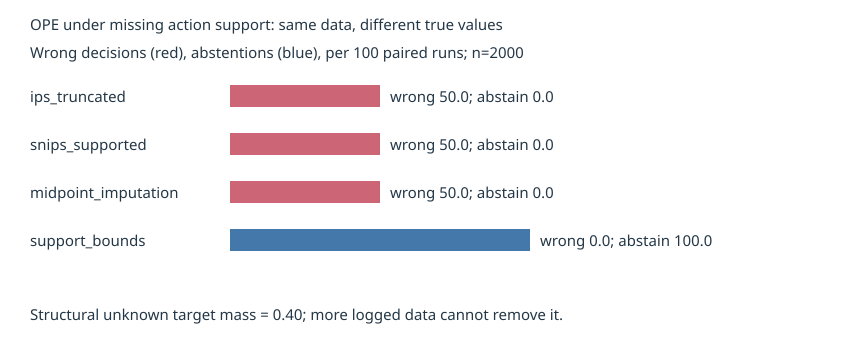

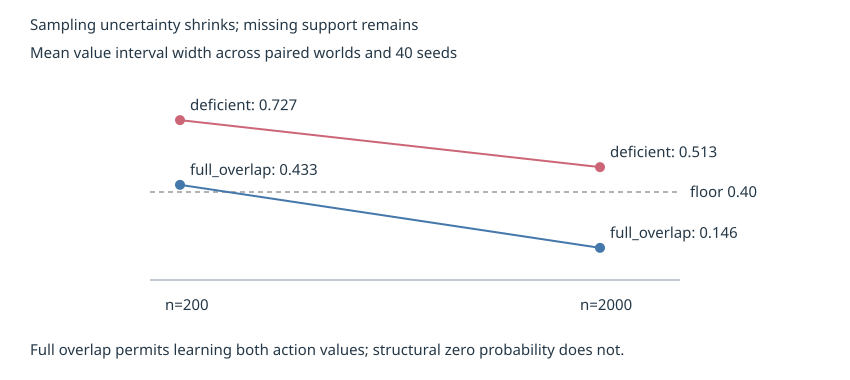

In [3]:
display(SVG(filename="results/support.svg"))
display(SVG(filename="results/width.svg"))

### Interpretación
La barra azul es una no-decisión justificada por información ausente. Con soporte completo la incertidumbre disminuye; con soporte deficiente no puede bajar del ancho estructural 0,40. Los bounds de confianza son conservadores y no se comparan por RMSE con puntos como si fueran el mismo producto.

In [4]:
import csv
raw=list(csv.DictReader(Path("results/raw.csv").open()))
bounds=[x for x in raw if x["method"]=="support_bounds"]
assert sum(int(x["covered"]) for x in bounds)/len(bounds)>=.95
assert all(int(x["wrong"])==0 for x in bounds)
assert all(float(x["width"])>=.4-1e-12 for x in bounds if x["regime"]=="deficient")
hi=[x for x in raw if x["method"]=="ips_truncated" and x["regime"]=="deficient" and x["world"]=="1.0" and x["n"]=="2000"]
assert sum(float(x["estimate"])-float(x["truth"]) for x in hi)/len(hi)<=-.3
print("Hipótesis sintética satisfecha. Cobertura empírica no certifica el uso fuera de supuestos.")
r["resources"]

Hipótesis sintética satisfecha. Cobertura empírica no certifica el uso fuera de supuestos.
Out[0]: 
[{'n': 200,
  'mean_seconds': 0.0006488172062603326,
  'seconds_se': 3.359566209703388e-05,
  'max_python_peak_bytes': 1528},
 {'n': 2000,
  'mean_seconds': 0.00531013203751769,
  'seconds_se': 0.00020339188065544427,
  'max_python_peak_bytes': 1248}]


## Conclusiones y siguiente prueba
Se necesitan exploración aprobada, restricciones de política o hipótesis justificadas de extrapolación para recuperar información ausente; normalizar IPS no crea soporte. Próxima iteración: políticas de logging con soporte pequeño positivo y comparación DR con modelos correctamente/mal especificados, separando identificabilidad de varianza. Ver referencias.bib para cinco trabajos OPE primarios y Hoeffding. Notebook ejecutado IPython in-process, no kernel aislado.